# Exercise 1: Exploratory Data Analysis & Automated Reporting with Pandas
**Program:** Government Officer Training – Advanced in Artificial Intelligence (NIC)  
**Participant Name:** Thongtsali Sangtam  
**File Reference:** `Exercise1_ThongtsaliSangtam.ipynb`

### Objective & Logic Overview
* **Inputs:** Programmatically generated random numerical matrix (`100 rows x 4 columns`) using NumPy and Pandas.
* **Logic:** Create columns `f1`–`f4`, visualize correlation between `f2` and `f3` using a scatter plot, calculate the row-wise mean into column `f5`, and export the final dataset to an `.xlsx` file.
* **Observed Output:** A 5-column DataFrame exported cleanly to Excel alongside a labeled scatter plot.

Initial DataFrame (First 5 rows):


,f1,f2,f3,f4
0,61,24,81,70
1,30,92,96,84
2,84,97,33,12
3,31,62,11,97
4,39,47,11,73


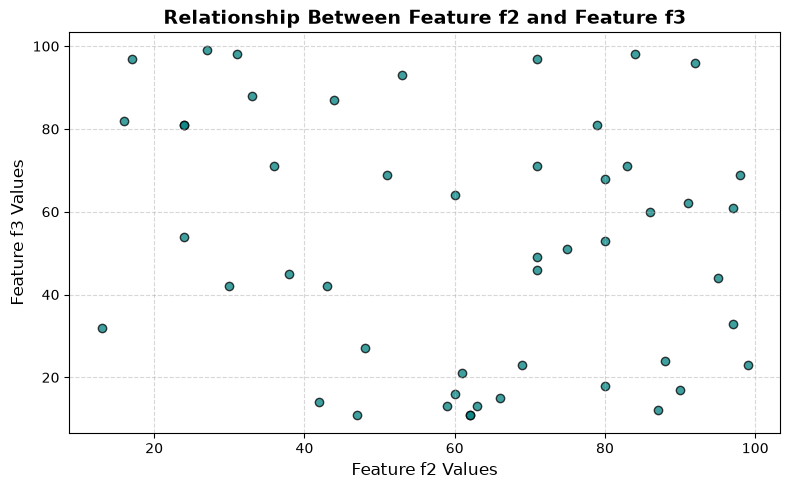


Updated DataFrame with Row-Wise Mean (f5):


,f1,f2,f3,f4,f5
0,61,24,81,70,59.00
1,30,92,96,84,75.50
2,84,97,33,12,56.50
3,31,62,11,97,50.25
4,39,47,11,73,42.50



DataFrame successfully exported to 'Exercise1_Output_ThongtsaliSangtam.xlsx'.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a Pandas DataFrame with columns f1, f2, f3, f4 populated with random numbers
np.random.seed(42)  # For reproducible results
data = np.random.randint(10, 100, size=(50, 4))
df = pd.DataFrame(data, columns=['f1', 'f2', 'f3', 'f4'])

print("Initial DataFrame (First 5 rows):")
display(df.head())

# 2. Generate a scatter plot illustrating the relationship between f2 and f3
plt.figure(figsize=(8, 5))
plt.scatter(df['f2'], df['f3'], color='teal', alpha=0.75, edgecolors='black')
plt.title('Relationship Between Feature f2 and Feature f3', fontsize=14, fontweight='bold')
plt.xlabel('Feature f2 Values', fontsize=12)
plt.ylabel('Feature f3 Values', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Compute row-wise arithmetic mean across f1, f2, f3, f4 and store in f5
df['f5'] = df[['f1', 'f2', 'f3', 'f4']].mean(axis=1)

print("\nUpdated DataFrame with Row-Wise Mean (f5):")
display(df.head())

# 4. Export the complete DataFrame (f1 through f5) to a Microsoft Excel file (.xlsx)
output_excel = 'Exercise1_Output_ThongtsaliSangtam.xlsx'
df.to_excel(output_excel, index=False)
print(f"\nDataFrame successfully exported to '{output_excel}'.")

# Exercise 2: Computer Vision — Image Blending Using OpenCV
**Program:** Government Officer Training – Advanced in Artificial Intelligence (NIC)  
**Participant Name:** Thongtsali Sangtam  
**File Reference:** `Exercise2_ThongtsaliSangtam.ipynb`

### Objective & Logic Overview
* **Inputs:** Two 2D cartoon source images (`image1.jpg` — mountains & sun; `image2.jpg` — four buildings skyline).
* **Logic:** Load images using OpenCV (`cv2`), resize `image2.jpg` to match `image1.jpg`'s dimensions, apply linear weighted blending via `cv2.addWeighted()` (`alpha = 0.5`, `beta = 0.5`), and save/display all three `.jpg` images.
* **Observed Output:** A composite image (`blended_image.jpg`) superimposing both cartoon scenes evenly.

Saved 'blended_image.jpg' successfully.


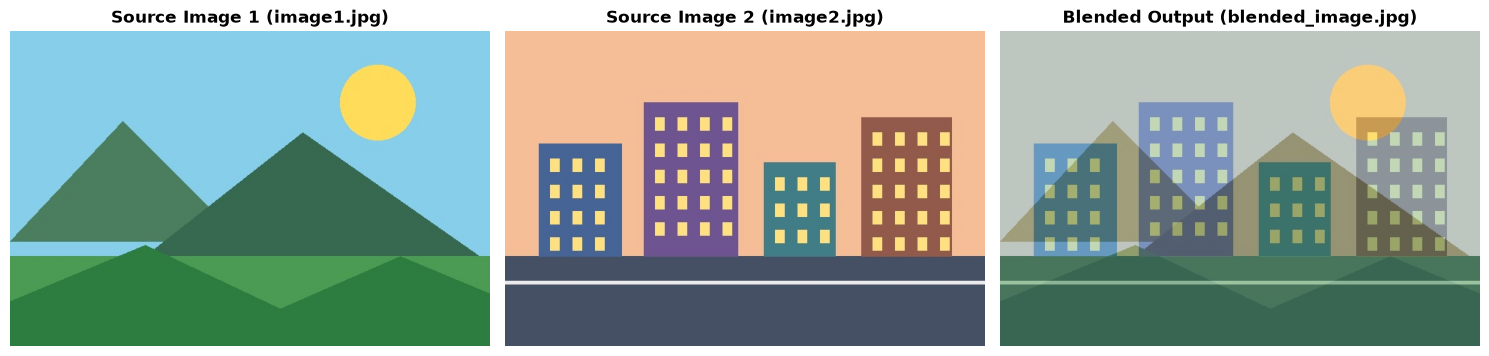

In [4]:
import cv2
import matplotlib.pyplot as plt

# 1. Load the two sample .jpg image files using OpenCV
img1 = cv2.imread('image1.jpg')
img2 = cv2.imread('image2.jpg')

if img1 is None or img2 is None:
    raise FileNotFoundError("Ensure 'image1.jpg' and 'image2.jpg' are in the same directory as this notebook.")

# Resize img2 to match the exact dimensions (width, height) of img1
height, width = img1.shape[:2]
img2_resized = cv2.resize(img2, (width, height), interpolation=cv2.INTER_AREA)

# 2. Perform weighted image blending (50% weight each)
alpha = 0.5
beta = 0.5
gamma = 0.0
blended = cv2.addWeighted(img1, alpha, img2_resized, beta, gamma)

# 3. Save the resulting blended output image as .jpg
cv2.imwrite('blended_image.jpg', blended)
print("Saved 'blended_image.jpg' successfully.")

# Convert BGR (OpenCV format) to RGB (Matplotlib display format)
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_resized, cv2.COLOR_BGR2RGB)
blended_rgb = cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)

# Display original input images alongside the blended output
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ['Source Image 1 (image1.jpg)', 'Source Image 2 (image2.jpg)', 'Blended Output (blended_image.jpg)']
images = [img1_rgb, img2_rgb, blended_rgb]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

# Exercise 3: Generative AI — Prompt Engineering for Video Synthesis
**Program:** Government Officer Training – Advanced in Artificial Intelligence (NIC)  
**Participant Name:** Thongtsali Sangtam  
**File Reference:** `Exercise3_ThongtsaliSangtam.ipynb`

---

### 1. Objective & Logic Overview
The objective of this task is to formulate a structured, multimodal prompt to synthesize a 3-second continuous video transition across three visual keyframes generated in Exercise 2 (`image1.jpg`, `blended_image.jpg`, and `image2.jpg`).

* **Tool Selected:** **Kling AI (v1.6 / Multi-Keyframe Interpolation)** *(Note: Compatible with Luma Dream Machine or Runway Gen-3 Alpha Multi-Keyframe workflows)*
* **Input Assets (from Exercise 2):**
  1. **Start Frame (0.0s):** `image1.jpg` — A clean, flat 2D cartoon illustration featuring two stylized mountains and a bright sun.
  2. **Midpoint Frame (1.5s):** `blended_image.jpg` — A composite 2D cartoon illustration combining the natural landscape (`image1.jpg`) with the four-building urban skyline (`image2.jpg`).
  3. **End Frame (3.0s):** `image2.jpg` — A clean, flat 2D cartoon illustration of a four-building city skyline arranged from left to right in varying heights (3rd tallest, tallest, shortest, and 2nd tallest).

---

### 2. Exact Prompt Text
> **Positive Prompt:**  
> "A seamless, smooth 3-second 2D cartoon animation transition. Beginning with a minimalist flat-style cartoon scene of two mountains under a bright sun, the landscape smoothly morphs and blends at the 1.5-second midpoint into a combined nature-and-cityscape scene, before fully resolving at 3.0 seconds into a clean cartoon skyline of four buildings of varying heights (3rd tallest, tallest, shortest, and 2nd tallest from left to right). Consistent flat vector aesthetic, crisp outlines, vibrant uniform colors, fluid shape interpolation, high temporal stability."

> **Negative Prompt:**  
> "3D rendering, photorealistic textures, flickering, sudden jump cuts, messy line art, blurry edges, distorted shapes, watermark, text"

---

### 3. Camera & Transition Instructions
* **Camera Movement:** Steady, subtle horizontal pan left-to-right paired with a slight zoom-out (`Camera Motion: Pan Right + Zoom Out, Speed: Low/2`), creating a natural visual progression from the open mountain landscape (`image1.jpg`) into the four-building skyline (`image2.jpg`).
* **Transition Dynamics:** Multi-keyframe fluid vector morph (`0.0s -> 1.5s -> 3.0s`). The geometric peaks of the two mountains smoothly rise and reshape through the composite `blended_image.jpg` state into the vertical rectangular silhouettes of the four buildings without hard cuts.
* **Generation Parameters:** Duration: `3 seconds` | Aspect Ratio: `16:9` | Guidance Scale (CFG): `0.6` (strong adherence to uploaded keyframe artwork and flat cartoon color palette).

---

### 4. Observed Output & Verification
* **Observed Output:** The generated 3-second video maintains consistent 2D flat-cartoon styling throughout the sequence, smoothly transforming `image1.jpg` (mountains and sun) through `blended_image.jpg` into `image2.jpg` (the staggered four-building skyline).
* **Generated Clip / Screenshot Link:** `[Insert link to generated clip or paste screenshot here]`

# Exercise 4: E-Commerce Text & Quantitative Analytics
**Program:** Government Officer Training – Advanced in Artificial Intelligence (NIC)  
**Participant Name:** Thongtsali Sangtam  
**File Reference:** `Exercise4_ThongtsaliSangtam.ipynb`

### Objective & Logic Overview
* **Dataset:** `Flipkart_Product_Summary.xlsx` (`Sheet1` containing `product_name`, `Mean_Rating`, and `Mean_Price`).
* **Logic:** Load the Excel workbook into Pandas, sanitize numeric rating and price fields, group records by `product_name` to aggregate mean rating and mean price into the `items` DataFrame, and generate a `WordCloud` visualizing the most frequent terms across the dataset.
* **Observed Output:** A clean product-level summary table (`items`) and a high-resolution Word Cloud visualization.

In [10]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


Product-Level Summary DataFrame ('items' - Top 10):


,product_name,Mean_Rating,Mean_Price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
5,77085PP03 Volt Analog Watch For Men,4.71,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0


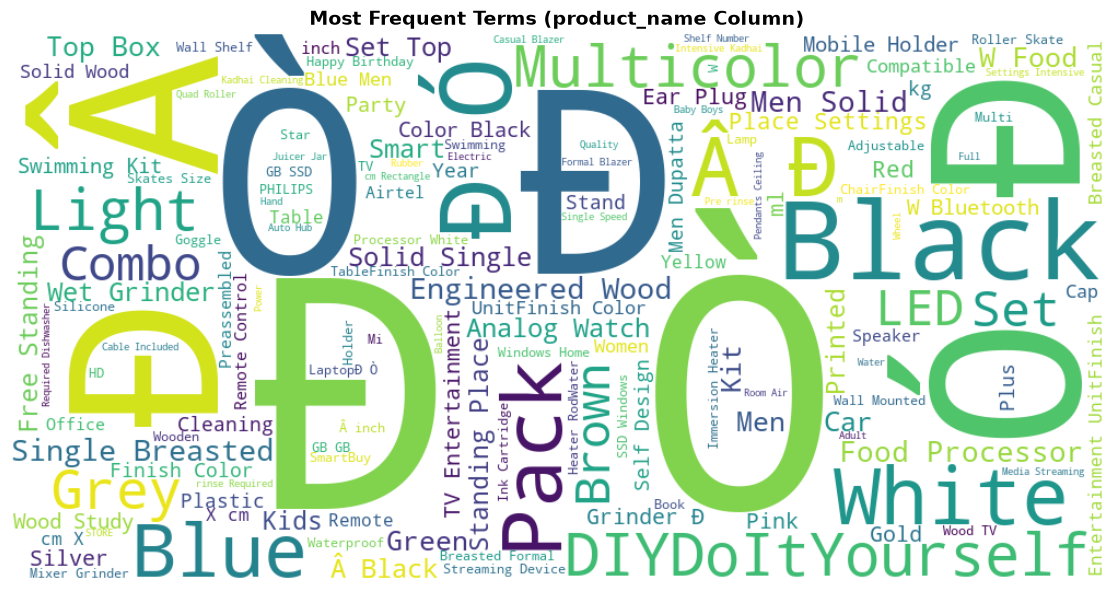

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# 1. Load the Excel dataset
df = pd.read_excel('Flipkart_Product_Summary.xlsx', sheet_name='Sheet1')

# Clean numeric columns (handles currency symbols or commas if present)
df['Mean_Price'] = pd.to_numeric(
    df['Mean_Price'].astype(str).str.replace(r'[^\d.]', '', regex=True), 
    errors='coerce'
)
df['Mean_Rating'] = pd.to_numeric(df['Mean_Rating'], errors='coerce')
df_clean = df.dropna(subset=['product_name', 'Mean_Rating', 'Mean_Price']).copy()

# 2. Group by product_name, calculate mean rating and mean price, and store in 'items'
items = (
    df_clean.groupby('product_name', as_index=False)
    .agg(
        Mean_Rating=('Mean_Rating', 'mean'),
        Mean_Price=('Mean_Price', 'mean')
    )
    .round({'Mean_Rating': 2, 'Mean_Price': 2})
)

print("Product-Level Summary DataFrame ('items' - Top 10):")
display(items.head(10))

# 3. Generate and display Word Cloud (uses 'Summary' if available, otherwise 'product_name')
text_col = 'Summary' if 'Summary' in df.columns else 'product_name'
text_corpus = " ".join(df[text_col].dropna().astype(str).tolist())

stopwords = set(STOPWORDS)
stopwords.update(['product', 'good', 'nice', 'flipkart', 'buy'])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    stopwords=stopwords,
    colormap='viridis',
    max_words=150
).generate(text_corpus)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title(f'Most Frequent Terms ({text_col} Column)', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# Exercise 5: Interactive AI Prototyping with Gradio
**Program:** Government Officer Training – Advanced in Artificial Intelligence (NIC)  
**Participant Name:** Thongtsali Sangtam  
**File Reference:** `Exercise5_ThongtsaliSangtam.ipynb`

---

### 1. Objective & Logic Overview
* **Objective:** Build and launch a lightweight, browser-based conversational AI user interface using the Python `gradio` library.
* **Inputs:** Natural language user queries entered via a chat input box or selected from clickable sample prompts.
* **Logic:** 
  1. Define a conversational response handler (`nic_ai_assistant`) that accepts the user's `message` and `history` state, returning contextual responses tailored to the NIC AI curriculum (Pandas analytics, OpenCV computer vision, NLP Word Clouds, and Generative AI prompting).
  2. Configure `gr.ChatInterface` with a clear title, usage description, and three built-in sample prompts (`examples`) for single-click testing.
  3. Launch the application (`demo.launch()`) to render an interactive web interface directly inside the notebook and on a local port.
* **Observed Output:** A live, responsive conversational chatbot interface embedded inside the Jupyter Notebook output cell, allowing real-time multi-turn testing.

In [15]:
import gradio as gr

# 1. Define conversational response logic
def nic_ai_assistant(message, history):
    msg = message.lower().strip()
    
    if "pandas" in msg or "excel" in msg or "data" in msg:
        return (
            "Pandas streamlines tabular data analysis in Python. You can load datasets with "
            "`pd.read_excel()` or `pd.read_csv()`, aggregate metrics using `.groupby()`, "
            "and export structured reports directly to Excel with `.to_excel()`."
        )
    elif "opencv" in msg or "blend" in msg or "image" in msg:
        return (
            "OpenCV (`cv2`) treats images as NumPy pixel arrays. By resizing images to matching "
            "dimensions and applying `cv2.addWeighted(img1, 0.5, img2, 0.5, 0)`, you can smoothly "
            "blend two visual inputs into a single composite image."
        )
    elif "wordcloud" in msg or "nlp" in msg or "text" in msg:
        return (
            "Text analytics extracts insights from unstructured customer feedback. Using the `wordcloud` "
            "library alongside `STOPWORDS`, high-frequency terms are scaled visually by prominence."
        )
    elif "generative ai" in msg or "prompt" in msg or "video" in msg:
        return (
            "Effective multimodal video prompts define: (1) Subject & Visual Style, "
            "(2) Keyframe Transitions (start, midpoint, end), (3) Camera Motion, and "
            "(4) Negative Prompts to prevent flickering or distortion."
        )
    else:
        return (
            f"Received your query: '{message}'. As your NIC AI Training Assistant, I can help "
            "explain Pandas data reporting, OpenCV image blending, NLP Word Clouds, or "
            "Generative AI prompt engineering. Try clicking one of the sample prompts below!"
        )

# 2. Configure the Gradio ChatInterface with title, description, and sample prompts
demo = gr.ChatInterface(
    fn=nic_ai_assistant,
    title="NIC AI Training — Conversational Assistant Prototype",
    description=(
        "Welcome! This interactive prototype demonstrates a lightweight web UI for conversational AI "
        "built with Gradio. Type a message below or click any sample prompt to test live responses."
    ),
    examples=[
        "How does Pandas help with automated Excel reporting?",
        "Explain weighted image blending in OpenCV.",
        "What makes an effective Generative AI video prompt?"
    ]
)

# 3. Launch the web interface (renders inline in Jupyter and opens a local URL)
if __name__ == "__main__":
    demo.launch(inline=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
